# [Forest Cover Type Prediction (Kaggle competition)](https://www.kaggle.com/competitions/forest-cover-type-prediction/)

Analytics Solutions Bootcamp Case Study 5A - DS Multiclass Classification Problem

---

In this problem, we need to predict the forest cover type (the predominant kind of tree cover) from cartographic variables. Each observation in our dataset corresponds to a $30\textrm{m} \times 30\textrm{m}$ patch of land located in the Roosevelt National Forest of northern Colorado. There are seven possible forest cover types:

1. **Spruce/Fir**
2. **Lodgepole Pine**
3. **Ponderosa Pine**
4. **Cottonwood/Willow**
5. **Aspen**
6. **Douglas-fir**
7. **Krummholz**

The training data consists of **15120** samples with **56** features (a mixture of both continuous and categorical data), including the **Cover_Type** represented by an integer $\{1,2,3,4,5,6,7\}$. Our task is to classify test samples by cover type (i.e. this is a multi-class classification task).

In [91]:
import warnings
from pathlib import Path
from pprint import pprint

import kagglehub
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.metrics import precision_score, recall_score, confusion_matrix, classification_report
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import cross_validate, GridSearchCV
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.inspection import permutation_importance

from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.simplefilter(action="ignore", category=FutureWarning)

SEED = 13

In [2]:
DATA_PATH = Path().cwd() / "data"

handle = "forest-cover-type-prediction"
dataset_dir = DATA_PATH / handle

if not dataset_dir.is_dir() or not any(dataset_dir.iterdir()):
    kagglehub.competition_download(
        handle=handle,
        output_dir=dataset_dir
    )
    print("Successfully saved files:", dataset_dir)
else:
    print("Files already exist:", dataset_dir)

Files already exist: D:\Users\Esperine\Workspace3\asb-main\cs5\data\forest-cover-type-prediction


## 1 - Loading and initial check

- Read the training data into a dataframe
- Check for missing (null) values
- Identify types of variable and their count

In [3]:
train_df = pd.read_csv(dataset_dir / "train.csv")
test_df = pd.read_csv(dataset_dir / "test.csv")

train_df.shape, test_df.shape

((15120, 56), (565892, 55))

In [4]:
train_df.head()

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,...,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,...,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,...,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,...,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,...,0,0,0,0,0,0,0,0,0,5


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15120 entries, 0 to 15119
Data columns (total 56 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Id                                  15120 non-null  int64
 1   Elevation                           15120 non-null  int64
 2   Aspect                              15120 non-null  int64
 3   Slope                               15120 non-null  int64
 4   Horizontal_Distance_To_Hydrology    15120 non-null  int64
 5   Vertical_Distance_To_Hydrology      15120 non-null  int64
 6   Horizontal_Distance_To_Roadways     15120 non-null  int64
 7   Hillshade_9am                       15120 non-null  int64
 8   Hillshade_Noon                      15120 non-null  int64
 9   Hillshade_3pm                       15120 non-null  int64
 10  Horizontal_Distance_To_Fire_Points  15120 non-null  int64
 11  Wilderness_Area1                    15120 non-null  int64
 12  Wilderness_Area

In [6]:
# Check how many unique values for each variable
train_df.nunique()

Id                                    15120
Elevation                              1665
Aspect                                  361
Slope                                    52
Horizontal_Distance_To_Hydrology        400
Vertical_Distance_To_Hydrology          423
Horizontal_Distance_To_Roadways        3250
Hillshade_9am                           176
Hillshade_Noon                          141
Hillshade_3pm                           247
Horizontal_Distance_To_Fire_Points     2710
Wilderness_Area1                          2
Wilderness_Area2                          2
Wilderness_Area3                          2
Wilderness_Area4                          2
Soil_Type1                                2
Soil_Type2                                2
Soil_Type3                                2
Soil_Type4                                2
Soil_Type5                                2
Soil_Type6                                2
Soil_Type7                                1
Soil_Type8                      

The unique ID of each observation is irrelevant to our goal and can be disregarded.

In [7]:
df = train_df.drop(labels="Id", axis=1)
print(df.shape)
df.head()

(15120, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


The dataset contains a mix of categorical and continuous variables as shown below. Their definition are presented in the [data section](https://www.kaggle.com/competitions/forest-cover-type-prediction/data) of the competition page.

In [8]:
categorical_variables = ["Cover_Type", "Wilderness_Area1", "Wilderness_Area2", "Wilderness_Area3", "Wilderness_Area4", "Soil_Type1", "Soil_Type2", "Soil_Type3", "Soil_Type4", "Soil_Type5", "Soil_Type6", "Soil_Type7", "Soil_Type8", "Soil_Type9", "Soil_Type10", "Soil_Type11", "Soil_Type12", "Soil_Type13", "Soil_Type14", "Soil_Type15", "Soil_Type16", "Soil_Type17", "Soil_Type18", "Soil_Type19", "Soil_Type20", "Soil_Type21", "Soil_Type22", "Soil_Type23", "Soil_Type24", "Soil_Type25", "Soil_Type26", "Soil_Type27", "Soil_Type28", "Soil_Type29", "Soil_Type30",  "Soil_Type31", "Soil_Type32", "Soil_Type33", "Soil_Type34", "Soil_Type35", "Soil_Type36", "Soil_Type37", "Soil_Type38", "Soil_Type39", "Soil_Type40"]

continuous_variables = ["Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology", "Vertical_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways", "Horizontal_Distance_To_Fire_Points", "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]

continuous_variables_labels = ["Elevation", "Aspect", "Slope", "Horizontal Dist. To Hydrology", "Vertical Dist. To Hydrology", "Horizontal Dist. To Roadways", "Horizontal Dist. To Fire Points", "Hillshade 9am", "Hillshade Noon", "Hillshade 3pm"]

print("Count of categorical variables:", len(categorical_variables))
print("Count of continuous variables:", len(continuous_variables))

Count of categorical variables: 45
Count of continuous variables: 10


## 2 - Data quality check and anomaly detection

- It's a good practice to check the quality of data before continuing with exploratory analysis and training.
- A production-grade data pipeline must verify physical plausibility, check for missing values, and audit the encoding of mutually exclusive categorical variables.

In [9]:
# Verify ID uniqueness and target schema
assert train_df["Id"].nunique() == len(train_df), "Duplicate IDs detected in train."
assert test_df["Id"].nunique() == len(test_df), "Duplicate IDs detected in test."
assert "Cover_Type" in train_df.columns and "Cover_Type" not in test_df.columns

# Missing value check
assert train_df.isna().sum().sum() == 0, "Missing values found."

# Mutually exclusive binary group audit
wilderness_cols = [f"Wilderness_Area{i}" for i in range(1, 5)]
soil_cols = [f"Soil_Type{i}" for i in range(1, 41)]

# Verify one-hot encoding integrity (row sums should equal 1)
wild_active = train_df[wilderness_cols].sum(axis=1)
soil_active = train_df[soil_cols].sum(axis=1)

print(f"Wilderness rows with != 1 active indicator: {(wild_active != 1).sum()}")
print(f"Soil rows with != 1 active indicator: {(soil_active != 1).sum()}")

# Check for physical domain boundaries
anomalies = {
    "negative_slope": (train_df["Slope"] < 0).sum(),
    "negative_h_dist_water": (train_df["Horizontal_Distance_To_Hydrology"] < 0).sum(),
    "negative_v_dist_water": (train_df["Vertical_Distance_To_Hydrology"] < 0).sum(),
    "hillshade_out_of_bounds": (
        (train_df[["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]] < 0) |
        (train_df[["Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm"]] > 255)
    ).sum().sum()
}
print("Physical domain anomalies:")
pprint(anomalies)

Wilderness rows with != 1 active indicator: 0
Soil rows with != 1 active indicator: 0
Physical domain anomalies:
{'hillshade_out_of_bounds': np.int64(0),
 'negative_h_dist_water': np.int64(0),
 'negative_slope': np.int64(0),
 'negative_v_dist_water': np.int64(1139)}


- We would see that `Vertical_Distance_To_Hydrology` contains negative numbers, however the values are physically valid.
- Note that a negative vertical distance indicates that the observation plot sits at an elevation below the nearest water source (e.g in a ravine or depression below an adjacent creek)

## 3 - Exploratory data analysis

### 3.1 - Cover types by wilderness area

- Check how many samples of each cover type there are.
- Note that the training set have equal numbers of each type.

In [10]:
df.groupby(["Cover_Type"]).size()

Cover_Type
1    2160
2    2160
3    2160
4    2160
5    2160
6    2160
7    2160
dtype: int64

Each sample is taken from one of four wilderness areas. Check where each of the cover types are found.

In [11]:
count_area_1 = df.groupby(["Cover_Type"]).sum()["Wilderness_Area1"]
count_area_2 = df.groupby(["Cover_Type"]).sum()["Wilderness_Area2"]
count_area_3 = df.groupby(["Cover_Type"]).sum()["Wilderness_Area3"]
count_area_4 = df.groupby(["Cover_Type"]).sum()["Wilderness_Area4"]

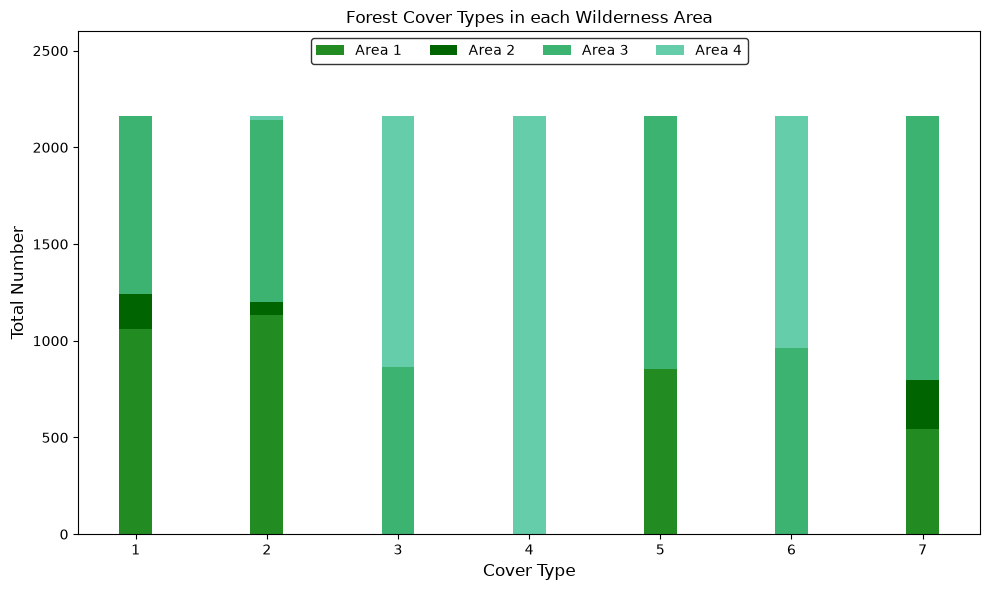

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

p1 = ax.bar(range(1,8), count_area_1, width=0.25, color="forestgreen", label="Area 1")
p2 = ax.bar(range(1,8), count_area_2, width=0.25, bottom=count_area_1, color="darkgreen", label="Area 2")
p3 = ax.bar(range(1,8), count_area_3, width=0.25, bottom=count_area_1+count_area_2, color="mediumseagreen", label="Area 3")
p4 = ax.bar(range(1,8), count_area_4, width=0.25, bottom=count_area_1+count_area_2+count_area_3, color="mediumaquamarine", label="Area 4")

ax.set_ylim([0, 2600])
ax.legend(ncol=4, loc="upper center", frameon=True, edgecolor="k")

ax.set_xlabel("Cover Type", fontsize=12)
ax.set_ylabel("Total Number", fontsize=12)
ax.set_title("Forest Cover Types in each Wilderness Area", fontsize=12)

fig.tight_layout()

### 3.2 - Distribution of continuous variables per cover type

- Let's look at the distributions of the different cover types with respect to each of the continuous variables.

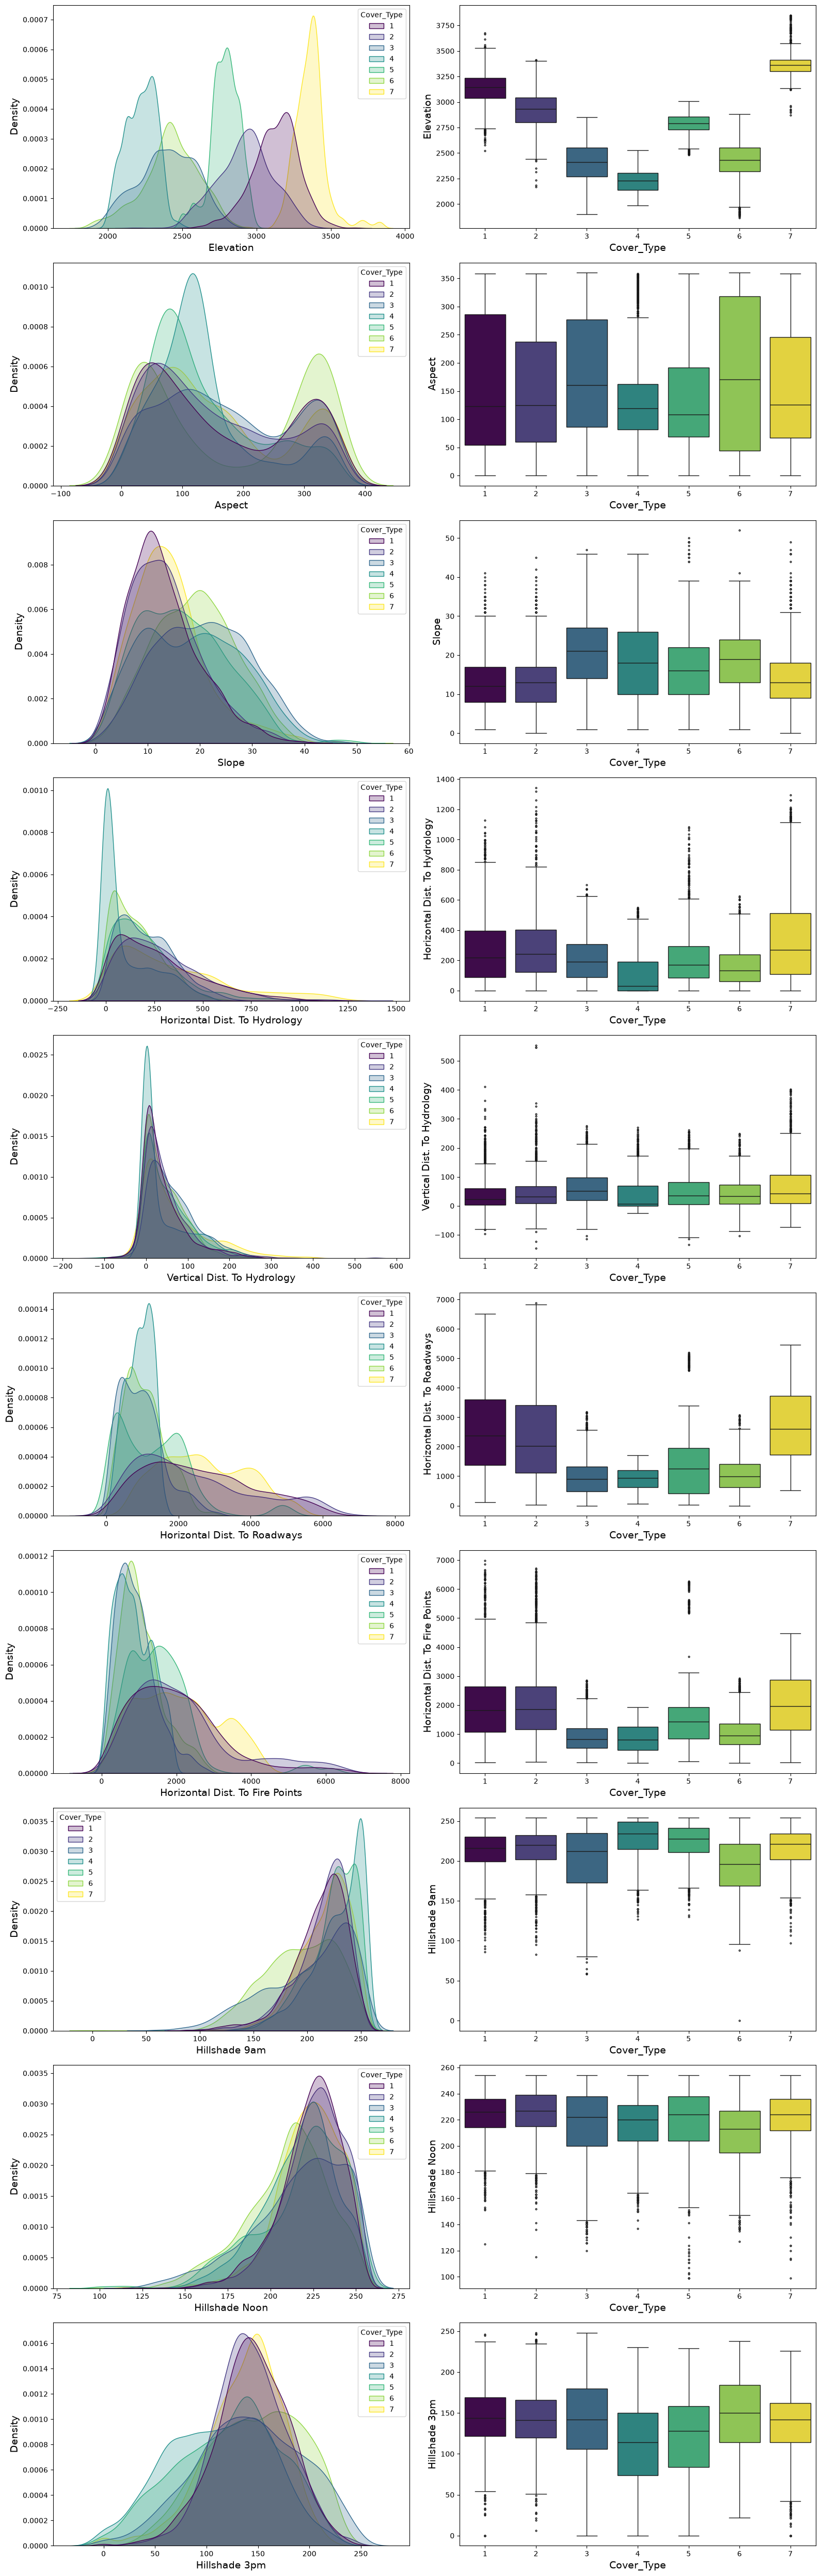

In [13]:
fig, axs = plt.subplots(nrows=10, ncols=2, figsize=(16,50))

for i in range(len(continuous_variables)):
    
    sns.kdeplot(data=df, x=continuous_variables[i], hue="Cover_Type", palette="viridis", fill=True, ax=axs[i][0])
    sns.boxplot(data=df, x="Cover_Type", y=continuous_variables[i], hue="Cover_Type", palette="viridis", fliersize=2, legend=False, ax=axs[i][1])
    
    axs[i][0].set_xlabel(continuous_variables_labels[i], fontsize=14)
    axs[i][1].set_ylabel(continuous_variables_labels[i], fontsize=14)
    axs[i][1].set_xlabel("Cover_Type", fontsize=14)
    axs[i][0].set_ylabel("Density", fontsize=14)

fig.subplots_adjust(left=0.1, bottom=0.1, right=0.9, top=0.9, wspace=0.4, hspace=0.3)
fig.tight_layout()

- The distribution plots clearly show that **Elevation** is quite important when it comes to statifiying the 7 cover types.
- For example, Krummholz (class 7) is evidently found at high elevation, with practically all observations occuring at elevations above 3000m. Its elevation distribution has no overlap with the lowest lying type, which is Cottonwood/Willow (class 4), which is mainly found below 2500m.
- We can take a closer look by obtaining the actual figures.

In [14]:
# Summary statistics of Elevation by Cover_Type
elevation_stats = df.groupby("Cover_Type")["Elevation"].agg(
    ["count", "mean", "std", "median", lambda x: np.percentile(x, 75) - np.percentile(x, 25)]
).rename(columns={"<lambda_0>": "IQR"})

elevation_stats.round(4)

,count,mean,std,median,IQR
Cover_Type,,,,,
1,2160,3128.0259,156.1250,3144.0,198.00
2,2160,2922.5403,185.7783,2931.5,240.00
3,2160,2398.4231,194.1081,2409.0,281.00
4,2160,2223.4204,102.9299,2230.5,164.25
5,2160,2786.8014,96.1775,2793.0,127.00
6,2160,2423.2769,188.9670,2430.0,233.25
7,2160,3362.7699,109.1268,3364.0,111.00


### 3.3 - Frequency of soil type

- There are 40 distinct soil types, each represented by a binary variable (1 or 9) depending on if a particular soil type is present.
- For each of the types of forest cover, check the most common soil types.

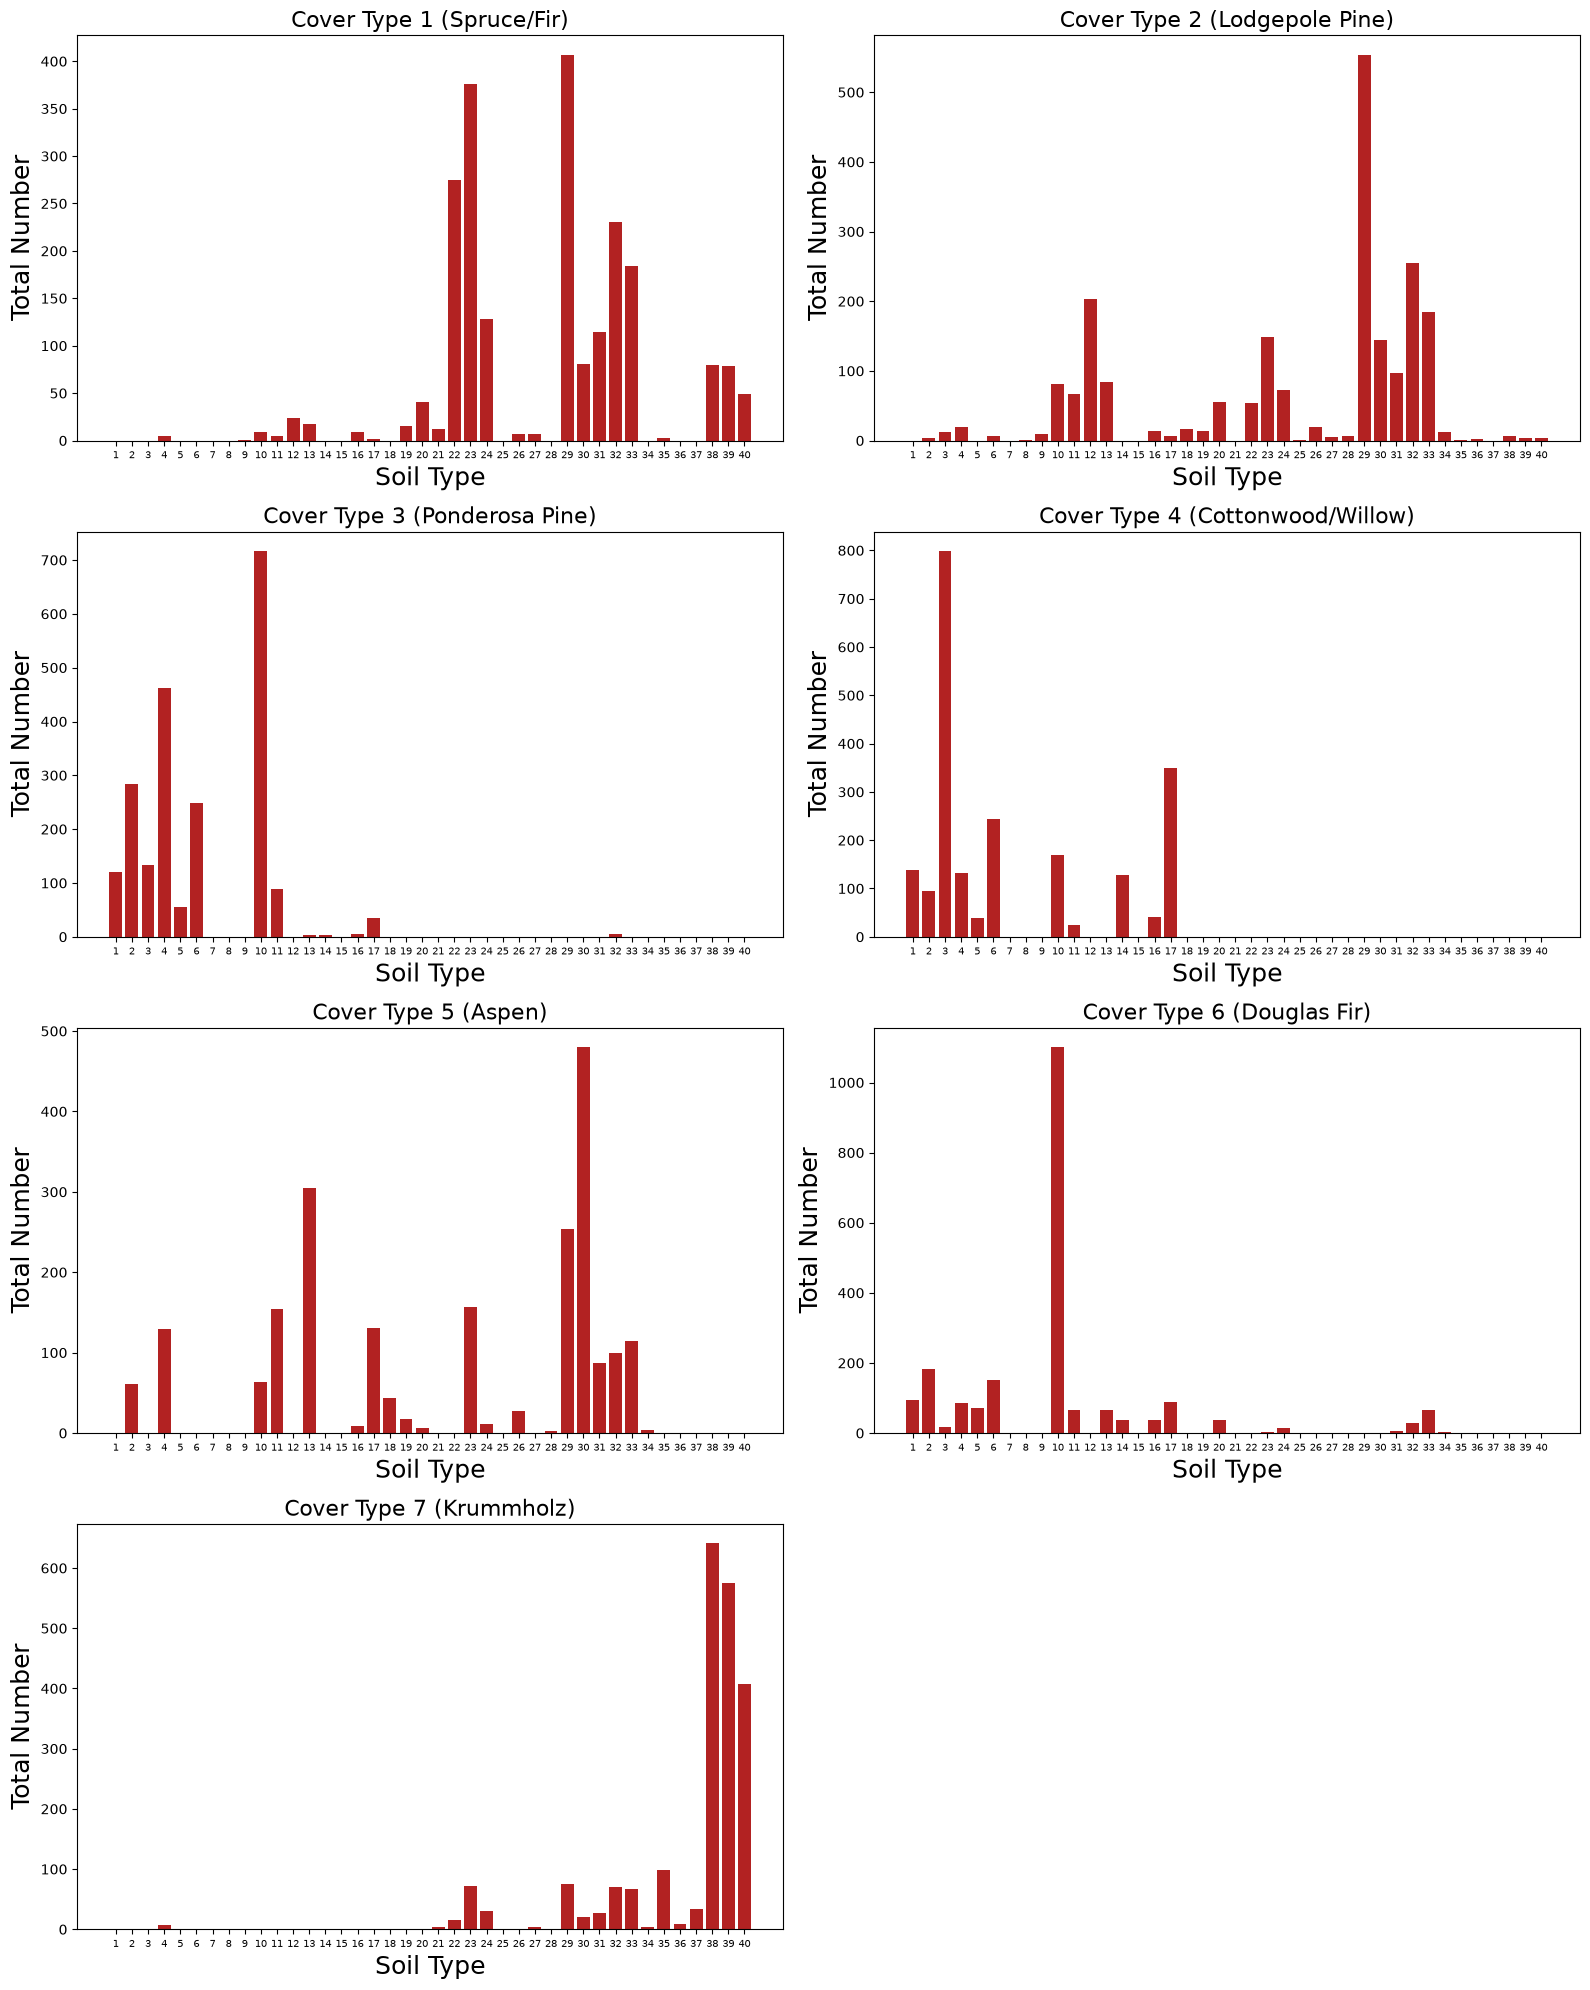

In [15]:
cover_df = df.groupby('Cover_Type').sum()

soil_1 =  np.array([cover_df['Soil_Type'+str(i)][1] for i in range(1,41)])
soil_2 =  np.array([cover_df['Soil_Type'+str(i)][2] for i in range(1,41)])
soil_3 =  np.array([cover_df['Soil_Type'+str(i)][3] for i in range(1,41)])
soil_4 =  np.array([cover_df['Soil_Type'+str(i)][4] for i in range(1,41)])
soil_5 =  np.array([cover_df['Soil_Type'+str(i)][5] for i in range(1,41)])
soil_6 =  np.array([cover_df['Soil_Type'+str(i)][6] for i in range(1,41)])
soil_7 =  np.array([cover_df['Soil_Type'+str(i)][7] for i in range(1,41)])

fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(16, 20))

axs[0][0].bar(x=list(range(1,41)), height=soil_1, color="firebrick")
axs[0][1].bar(x=list(range(1,41)), height=soil_2, color="firebrick")
axs[1][0].bar(x=list(range(1,41)), height=soil_3, color="firebrick")
axs[1][1].bar(x=list(range(1,41)), height=soil_4, color="firebrick")
axs[2][0].bar(x=list(range(1,41)), height=soil_5, color="firebrick")
axs[2][1].bar(x=list(range(1,41)), height=soil_6, color="firebrick")
axs[3][0].bar(x=list(range(1,41)), height=soil_7, color="firebrick")
axs[3][1].axis("off")

axs[0][0].set_title("Cover Type 1 (Spruce/Fir)", fontsize=16)
axs[0][1].set_title("Cover Type 2 (Lodgepole Pine)", fontsize=16)
axs[1][0].set_title("Cover Type 3 (Ponderosa Pine)", fontsize=16)
axs[1][1].set_title("Cover Type 4 (Cottonwood/Willow)", fontsize=16)
axs[2][0].set_title("Cover Type 5 (Aspen)", fontsize=16)
axs[2][1].set_title("Cover Type 6 (Douglas Fir)", fontsize=16)
axs[3][0].set_title("Cover Type 7 (Krummholz)", fontsize=16)

for i in range(4):
    for j in range(2):
        axs[i][j].set_xticks(list(range(1,41)))
        axs[i][j].set_xticklabels(labels=list(range(1,41)), fontsize=7.5)
        axs[i][j].set_xlabel("Soil Type", fontsize=18)
        axs[i][j].set_ylabel("Total Number", fontsize=18)

fig.subplots_adjust(left=0.05, bottom=0.05, right=0.95, top=0.95, wspace=0.2, hspace=0.45)
fig.tight_layout()

### 3.4 - Correlation heatmap for continuous variables

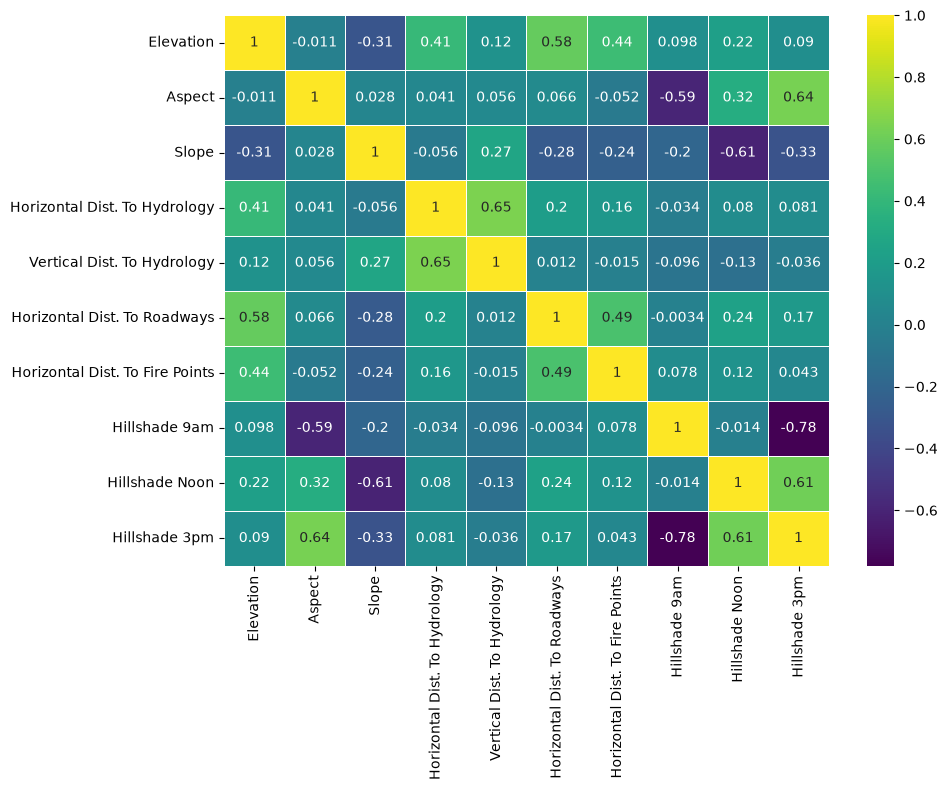

In [16]:
corr = df[continuous_variables].corr()

fig, ax = plt.subplots(figsize=(10,8))

sns.heatmap(
    corr, 
    xticklabels=continuous_variables_labels, 
    yticklabels=continuous_variables_labels, 
    linewidths=0.5, 
    cmap="viridis", 
    annot=True
)

fig.tight_layout()

In [17]:
corr_upper_tri = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
threshold = 0.7
high_corr = corr_upper_tri.unstack().dropna()
high_corr_pairs = high_corr[high_corr.abs() > threshold]

high_corr_pairs

Hillshade_3pm  Hillshade_9am   -0.779965
dtype: float64

In [18]:
threshold = 0.6
high_corr = corr_upper_tri.unstack().dropna()
strong_pairs = high_corr[high_corr.abs() > threshold]

strong_pairs

Vertical_Distance_To_Hydrology  Horizontal_Distance_To_Hydrology    0.652142
Hillshade_Noon                  Slope                              -0.612613
Hillshade_3pm                   Aspect                              0.635022
                                Hillshade_9am                      -0.779965
                                Hillshade_Noon                      0.614526
dtype: float64

Some of continuous features seem to have little correlation with one another, for instance, `Elevation` and `Vertical_Distance_To_Hydrology`. However, we can check whether a jointplot of these variables, distinguishing data points by their cover type, could reveal any hidden structure. 

### 3.5 - Jointplots of continuous variables

Consider `Vertical_Distance_To_Hydrology` vs. `Horizontal_Distance_To_Hydrology`

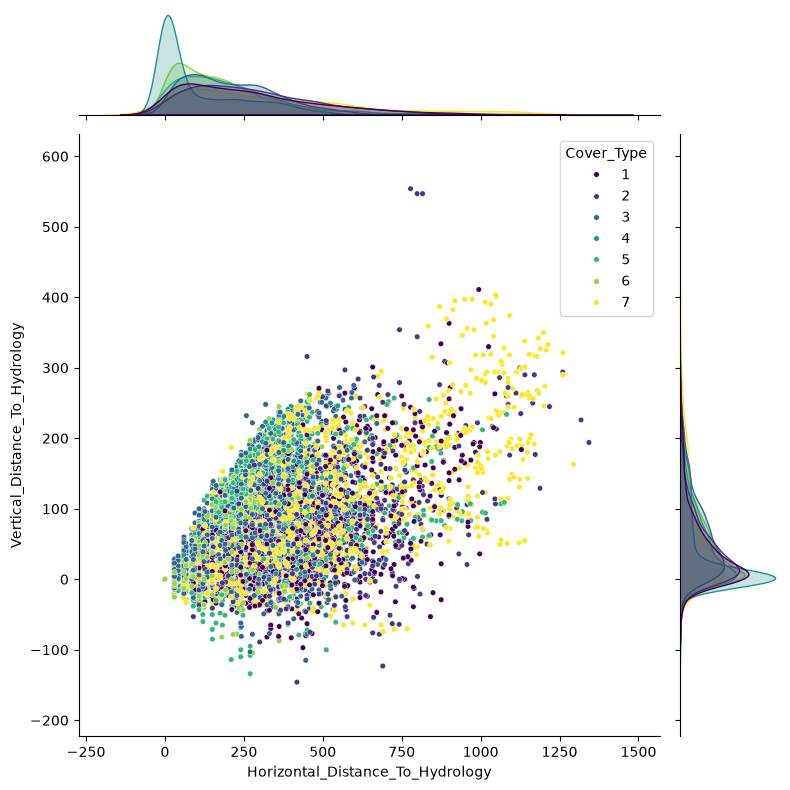

In [19]:
sns.jointplot(
    data=df, 
    x="Horizontal_Distance_To_Hydrology", 
    y="Vertical_Distance_To_Hydrology", 
    hue="Cover_Type", 
    palette="viridis", 
    height=8, 
    s=16
)

plt.tight_layout()

- Considering the 0.65 correlation coefficient between the two variables, we do see a strong positive correlation.
- It may be useful to derive a feature representing the total distance to hydology by combining the squares of these variables.

Consider `Elevation` vs. `Horizontal_Distance_To_Roadways` 

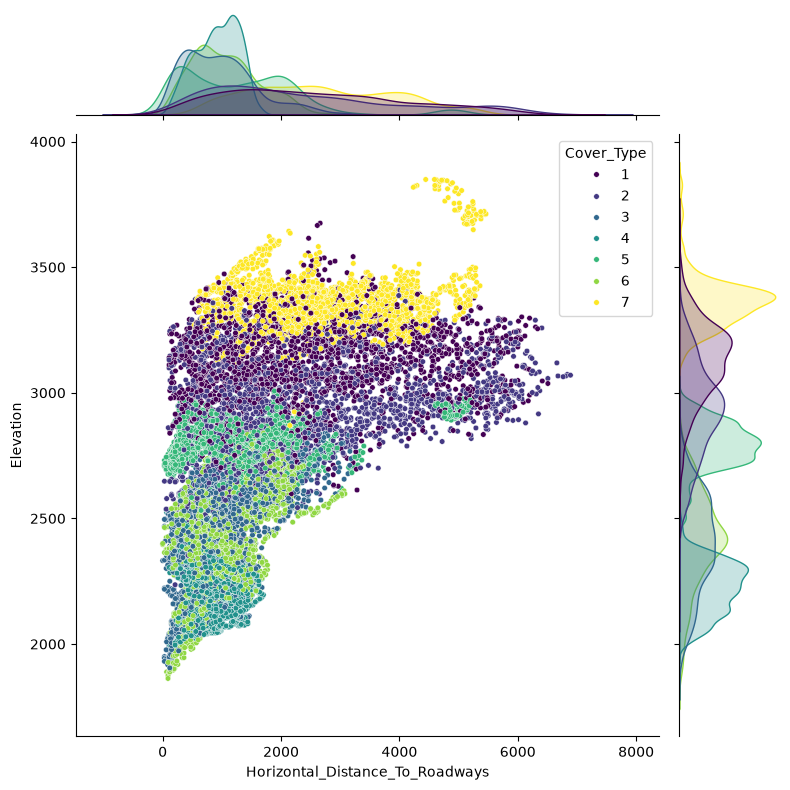

In [20]:
sns.jointplot(
    data=df, 
    x="Horizontal_Distance_To_Roadways", 
    y="Elevation", 
    hue="Cover_Type", 
    palette="viridis", 
    height=8, 
    s=16
)

plt.tight_layout()

Consider `Elevation` vs. `Slope`

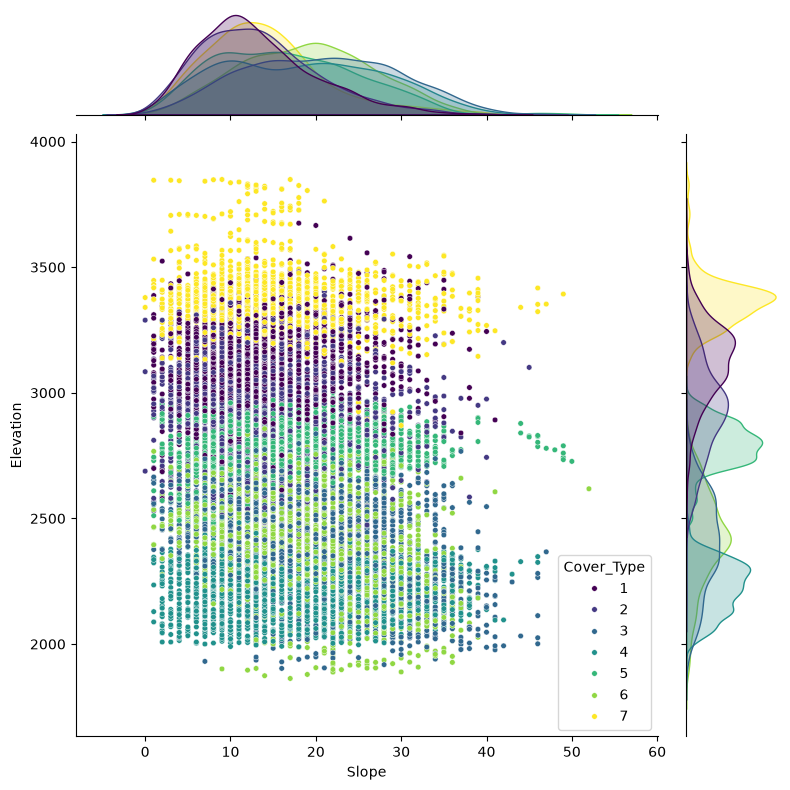

In [21]:
sns.jointplot(
    data=df, 
    x="Slope", 
    y="Elevation", 
    hue="Cover_Type", 
    palette="viridis", 
    height=8, 
    s=16
)

plt.tight_layout()

- The two previous plots show how useful is `Elevation` for separating the different cover types.
- Other continuous variables such as `Slope` may not be as useful since for any given slope, we observe examples of essentially all cover types.
- There are other continuous variables such as `Horizontal_Distance_To_Roadways` also somewhat separate cover types.

Consider `Elevation` vs. `Vertical_Distance_To_Hydrology`

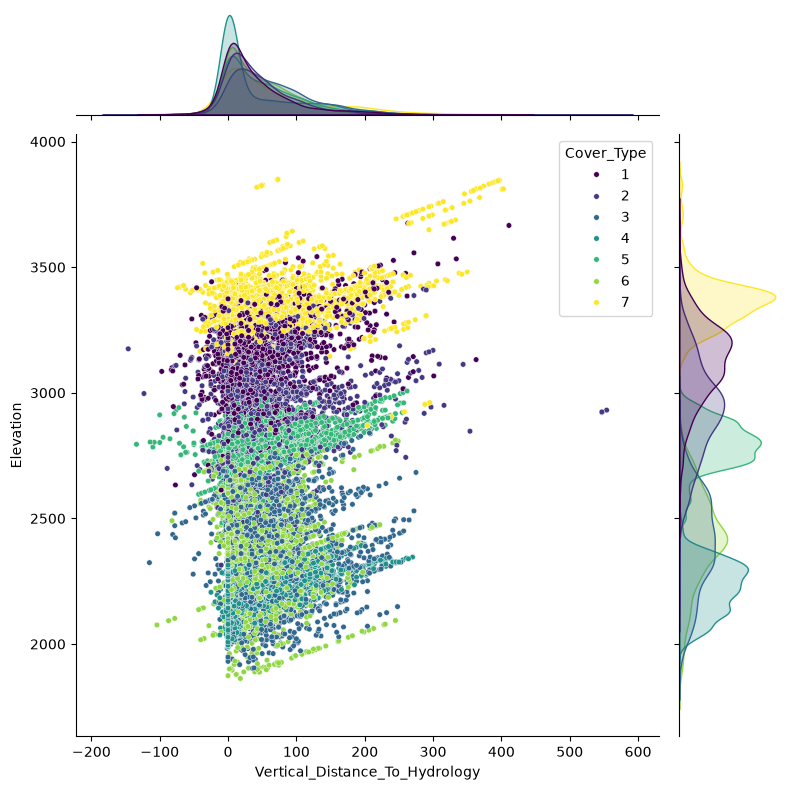

In [22]:
sns.jointplot(
    data=df, 
    x="Vertical_Distance_To_Hydrology", 
    y="Elevation", 
    hue="Cover_Type", 
    palette="viridis", 
    height=8, 
    s=16
)

plt.tight_layout()

- Based on the correlation values, there is little correlation between `Elevation` and `Vertical_Distance_To_Hydrology` when one combines data for all cover types.
- By distinguishing them by cover type, we can see some pattern. It appears that there are distinct sets of observations which fall along lines of positive slop, with each set belonging to a particlar cover type.
- We can consider deriving new features later on, which are linear combinations of two variables. For example, defining a feature which is the difference of `Elevation` and `Vertical_Distance_To_Hydrology` may help stratify the data by cover type better than `Vertical_Distance_To_Hydrology` alone.

Consider `Horizontal_Distance_To_Fire_Points` vs. `Horizontal_Distance_To_Hydrology`

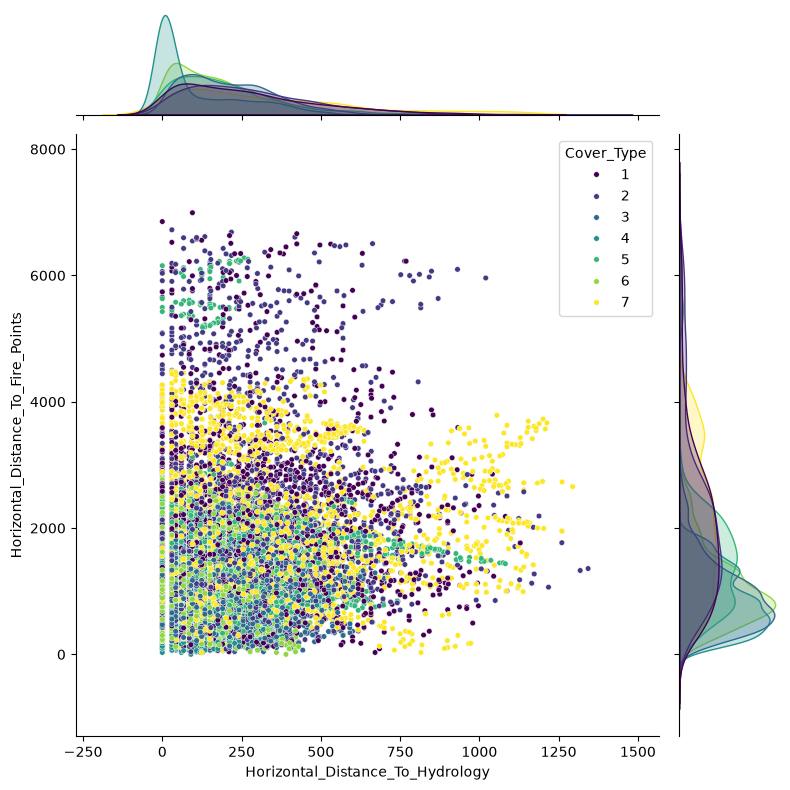

In [23]:
sns.jointplot(
    data=df, 
    x="Horizontal_Distance_To_Hydrology", 
    y="Horizontal_Distance_To_Fire_Points", 
    hue="Cover_Type", 
    palette="viridis", 
    height=8, 
    s=16
)

plt.tight_layout()

Consider `Horizontal_Distance_To_Roadways` vs `Horizontal_Distance_To_Hydrology`

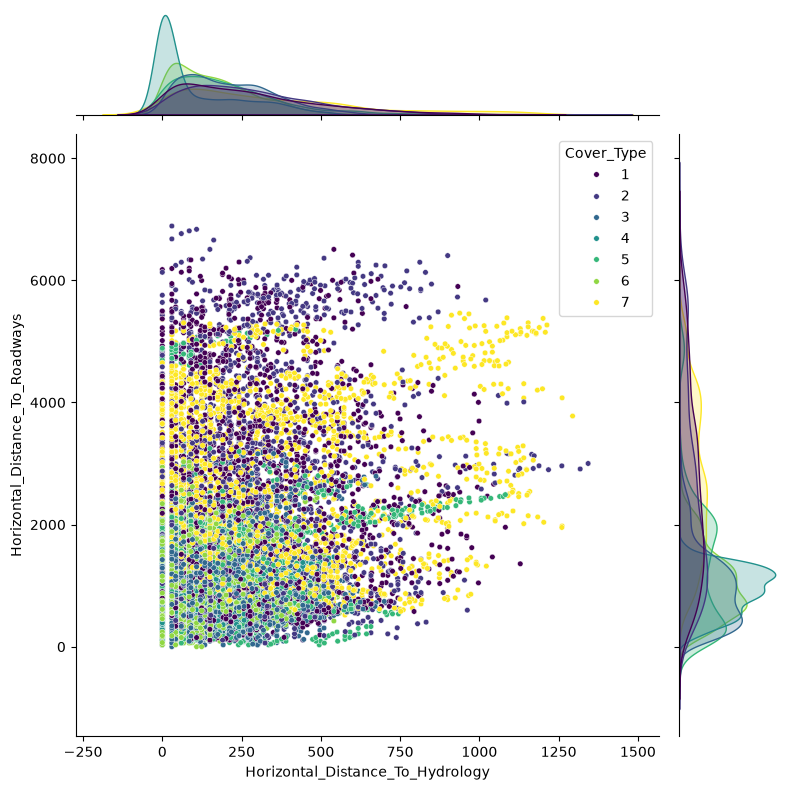

In [24]:
sns.jointplot(
    data=df, 
    x="Horizontal_Distance_To_Hydrology", 
    y="Horizontal_Distance_To_Roadways", 
    hue="Cover_Type", 
    palette="viridis", 
    height=8, 
    s=16
)

plt.tight_layout()

Consider `Horizontal_Distance_To_Roadways` vs. `Horizontal_Distance_To_Fire_Points`

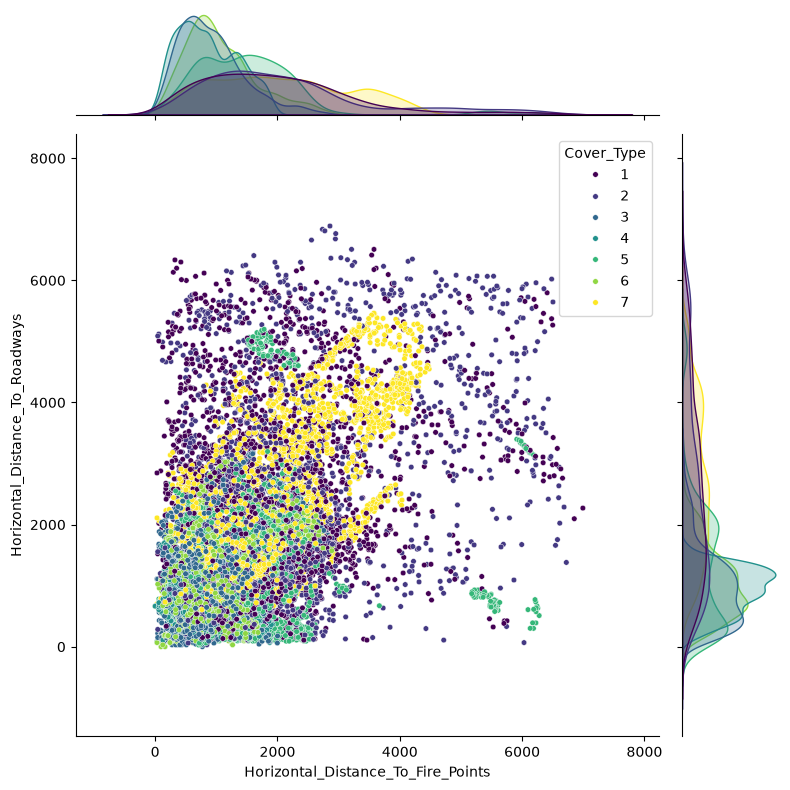

In [25]:
sns.jointplot(
    data=df, 
    x="Horizontal_Distance_To_Fire_Points", 
    y="Horizontal_Distance_To_Roadways", 
    hue="Cover_Type", 
    palette="viridis", 
    height=8, 
    s=16
)

plt.tight_layout()

Like before, The last three jointplots appear to show that there are distinct sets of observations which fall along lines of positive or negative slope, with each set belonging to a particular cover type.

## 4 - Feature engineering

- Let's try deriving features which we'll see if it helps achieve higher accuracy.
- Aside from linear combinations of the existing variables, we will derive domain-informed features to represent physical relationships and circular geometry.
- As an example for interpretation, the difference of `Elevation` and `Vertical_Distance_To_Hydrology` represents the absolute elevation of the water body while the sum of the two represents relative topographic position or ridge exposure.
- The approach here would be creating a function that handles the transformation logic in the pipeline.

In [26]:
def setup_features(X: pd.DataFrame) -> pd.DataFrame:
    X_out = X.copy()

    # Euclidean distance to hydrology
    X_out["Dist_Hydrology"] = np.sqrt(
        X_out["Horizontal_Distance_To_Hydrology"]**2 + 
        X_out["Vertical_Distance_To_Hydrology"]**2
    )

    # Elevation of body of water
    X_out["Water_Body_Elevation"] = (
        X_out["Elevation"] - X_out["Vertical_Distance_To_Hydrology"]
    )

    # Relative topographic position to body of water
    X_out["Water_Body_Relative_Topographic_Position"] = (
        X_out["Elevation"] + X_out["Vertical_Distance_To_Hydrology"]
    )

    # Cyclical aspect transformations
    aspect_rad = np.radians(X_out["Aspect"])
    X_out["Aspect_Sin"] = np.sin(aspect_rad)
    X_out["Aspect_Cos"] = np.cos(aspect_rad)

    # Solar variation / Shading dynamic
    X_out["Hillshade_Spread_3pm_9am"] = (
        X_out["Hillshade_3pm"] - X_out["Hillshade_9am"]
    )
    X_out["Hillshade_Spread_Noon_3pm"] = (
        X_out["Hillshade_Noon"] - X_out["Hillshade_3pm"]
    )

    # Amenities proximity
    X_out["Mean_Dist_Amenities"] = (
        X_out["Horizontal_Distance_To_Roadways"] + 
        X_out["Horizontal_Distance_To_Fire_Points"] +
        X_out["Horizontal_Distance_To_Hydrology"]
    ) / 3.0

    # Spatial distances
    X_out["Hydrology_Plus_Fire_Points"] = (
        X_out["Horizontal_Distance_To_Hydrology"] +
        X_out["Horizontal_Distance_To_Fire_Points"]
    )
    X_out["Hydrology_Minus_Fire_Points"] = (
        X_out["Horizontal_Distance_To_Hydrology"] -
        X_out["Horizontal_Distance_To_Fire_Points"]
    )
    X_out["Hydrology_Plus_Roadways"] = (
        X_out["Horizontal_Distance_To_Hydrology"] +
        X_out["Horizontal_Distance_To_Roadways"]
    )
    X_out["Hydrology_Minus_Roadways"] = (
        X_out["Horizontal_Distance_To_Hydrology"] -
        X_out["Horizontal_Distance_To_Roadways"]
    )
    X_out["Fire_Points_Plus_Roadways"] = (
        X_out["Horizontal_Distance_To_Fire_Points"] +
        X_out["Horizontal_Distance_To_Roadways"]
    )
    X_out["Fire_Points_Minus_Roadways"] = (
        X_out["Horizontal_Distance_To_Fire_Points"] -
        X_out["Horizontal_Distance_To_Roadways"]
    )

    return X_out

created_variables = [
    "Dist_Hydrology",
    "Water_Body_Elevation",
    "Water_Body_Relative_Topographic_Position",
    "Aspect_Sin",
    "Aspect_Cos",
    "Hillshade_Spread_3pm_9am",
    "Hillshade_Spread_Noon_3pm",
    "Mean_Dist_Amenities",
    "Hydrology_Plus_Fire_Points",
    "Hydrology_Minus_Fire_Points",
    "Hydrology_Plus_Roadways",
    "Hydrology_Minus_Roadways",
    "Fire_Points_Plus_Roadways",
    "Fire_Points_Minus_Roadways"
]

created_variables_labels = [
    "Distance to Hydrology",
    "Elevation of Water Body",
    "Relative Topographic Position of Water Body",
    "Sin of Aspect",
    "Cosine of Aspect",
    "Hillside Spread 3 PM - 9 AM",
    "Hillside Spread 12 PM - 3 PM",
    "Mean Distance Near Amenities",
    "Distance Hydrology Plus Fire Points",
    "Distance Hydrology Minus Fire Points",
    "Distance Hydrology Plus Roadways",
    "Distance Hydrology Minus Roadways",
    "Distance Fire Points Plus Roadways",
    "Distance Fire Points Minus Roadways"
]

## 5 - Training and validation setup

- No need to prepare a test set since a separate test data is provided.
- There are two acceptable approach:
    1. Single stratified train-validation split
    2. Stratified cross-validation
- For our setup, consider a **5-fold stratified cross-validation**.

$$\text{Folds} = 5, \quad N_{\text{val\_fold}} = \frac{15{,}120}{5} = 3{,}024 \quad \text{observations per fold}$$

In [27]:
df.columns

Index(['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology',
       'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways',
       'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
       'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area1',
       'Wilderness_Area2', 'Wilderness_Area3', 'Wilderness_Area4',
       'Soil_Type1', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type5',
       'Soil_Type6', 'Soil_Type7', 'Soil_Type8', 'Soil_Type9', 'Soil_Type10',
       'Soil_Type11', 'Soil_Type12', 'Soil_Type13', 'Soil_Type14',
       'Soil_Type15', 'Soil_Type16', 'Soil_Type17', 'Soil_Type18',
       'Soil_Type19', 'Soil_Type20', 'Soil_Type21', 'Soil_Type22',
       'Soil_Type23', 'Soil_Type24', 'Soil_Type25', 'Soil_Type26',
       'Soil_Type27', 'Soil_Type28', 'Soil_Type29', 'Soil_Type30',
       'Soil_Type31', 'Soil_Type32', 'Soil_Type33', 'Soil_Type34',
       'Soil_Type35', 'Soil_Type36', 'Soil_Type37', 'Soil_Type38',
       'Soil_Type39', 'Soil_Type40

In [28]:
target = "Cover_Type"
features_X = df.drop(columns=target)
target_y = df[target]

features_X.shape, target_y.shape

((15120, 54), (15120,))

In [29]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
skf

StratifiedKFold(n_splits=5, random_state=13, shuffle=True)

## 6 - Baseline benchmark

The zero-rule baseline always predicts the most frequent class in the training split. Because all 7 classes have exactly 2160 rows in the training data (i.e equal proportion), predicting class 1 (or any class uniformly) yields the following.

$$\text{Accuracy}_{\text{base}} = \frac{1}{7} \approx 14.29\% \quad$$

$$\text{Macro } F_1 = \frac{1}{7} \times \left( \frac{2 \times \frac{1}{7} \times 1}{\frac{1}{7} + 1} \right) + \sum_{k=2}^7 0 = \frac{1}{7} \times 0.25 = 0.0357 \quad (3.57\%)$$

In [30]:
model_baseline = Pipeline(steps=[
    ("apply_fe", FunctionTransformer(setup_features)),
    ("scaler", StandardScaler()),
    ("model", DummyClassifier(strategy="most_frequent"))
])

model_baseline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('apply_fe', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function set...002223D2B33D0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionar

In [31]:
scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

cv_results = cross_validate(
    estimator=model_baseline,
    X=features_X,
    y=target_y,
    cv=skf,
    scoring=scoring
)

mean_acc = np.mean(cv_results["test_accuracy"])
std_acc = np.std(cv_results["test_accuracy"])
mean_f1 = np.mean(cv_results["test_macro_f1"])
std_f1 = np.std(cv_results["test_macro_f1"])

print(f"Zero-rule Accuracy: {mean_acc:.4f} ± {std_acc:.4f}")
print(f"Zero-rule Macro F1: {mean_f1:.4f} ± {std_f1:.4f}")

Zero-rule Accuracy: 0.1429 ± 0.0000
Zero-rule Macro F1: 0.0357 ± 0.0000


## 7 - Model training and hyperparameter tuning

- We first prepare helper functions to conveniently obtain scores and analyze performance for each candidate model.
- Metrics used: **Accuracy, F1 score, Precision, Recall, ROC AUC**
- For distance-based models, we need to apply a scaler to standardize continuous variables. As for tree-based models, they don't need one because they're invariant to monotonic feature scaling.

In [32]:
def get_metrics(model, X_test, y_test):
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")
    precision = precision_score(y_test, y_pred, average="weighted")
    recall = recall_score(y_test, y_pred, average="weighted")

    return accuracy, precision, recall, f1


def predict(model, X_test, y_test):
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("F1 score (weighted average): ", f1_score(y_test, y_pred, average="weighted"))
    print(
        "Precision (weighted average): ",
        precision_score(y_test, y_pred, average="weighted"),
    )
    print(
        "Recall (weighted average): ", recall_score(y_test, y_pred, average="weighted")
    )
    return y_pred


def plot_confusion_matrix(model, X_test, y_test, title):
    y_pred = model.predict(X_test)

    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="YlGnBu")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(title)
    plt.xticks(
        ticks=np.array(range(7)) + 0.5, labels=["1", "2", "3", "4", "5", "6", "7"]
    )
    plt.yticks(
        ticks=np.array(range(7)) + 0.5, labels=["1", "2", "3", "4", "5", "6", "7"]
    )
    plt.tight_layout()


def plot_roc_curves(model, X_test, y_test, title):
    plt.figure(figsize=(8, 3.5))

    for i in range(7):
        cover = i + 1

        y_test_proba = model.predict_proba(X_test)
        auc_test = roc_auc_score(
            y_test == cover, y_test_proba[:, i], multi_class="multinomial"
        )
        y_test_fpr, y_test_tpr, _ = roc_curve(y_test == cover, y_test_proba[:, i])

        plt.plot(
            y_test_fpr,
            y_test_tpr,
            marker=None,
            linewidth=1.5,
            label=f"Cover Type {cover}, AUC: {np.round(auc_test, 4)}",
        )

        plt.ylabel("True Positive Rate (Recall)", fontsize=12)
        plt.xlabel("False Positive Rate", fontsize=12)

        plt.legend(frameon=True, edgecolor="k", fontsize=9)

        plt.title(title)

    plt.tight_layout()



In [33]:
grid_search_result_metrics = [
    "mean_test_accuracy",
    "std_test_accuracy",
    "mean_test_macro_f1",
    "std_test_macro_f1",
    "rank_test_accuracy",
    "rank_test_macro_f1"
]

summary_metrics = [
    "accuracy_mean", 
    "accuracy_std", 
    "macro_f1_mean", 
    "macro_f1_std"
]

def grid_search_result_summary(grid_search: GridSearchCV, model_name: str):
    print("Model:", model_name)
    print("Best params:")
    pprint(grid_search.best_params_)
    print("Best score:", grid_search.best_score_)

### 7.1 - Logistic Regression

In [34]:
model = Pipeline(steps=[
    ("apply_fe", FunctionTransformer(setup_features)),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=SEED))
])

params_lr = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

result_cv_lr = GridSearchCV(
    estimator=model,
    param_grid=params_lr,
    cv=skf,
    scoring=scoring,
    refit="macro_f1",
    verbose=2
)

result_cv_lr.fit(features_X, target_y)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[CV] END .....................................model__C=0.001; total time=   0.0s
[CV] END .....................................model__C=0.001; total time=   0.0s
[CV] END .....................................model__C=0.001; total time=   0.0s
[CV] END .....................................model__C=0.001; total time=   0.0s
[CV] END .....................................model__C=0.001; total time=   0.0s
[CV] END ......................................model__C=0.01; total time=   0.1s
[CV] END ......................................model__C=0.01; total time=   0.1s
[CV] END ......................................model__C=0.01; total time=   0.1s
[CV] END ......................................model__C=0.01; total time=   0.1s
[CV] END ......................................model__C=0.01; total time=   0.1s
[CV] END .......................................model__C=0.1; total time=   0.2s
[CV] END .......................................m

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'macro_f1': 'f1_macro'}"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'macro_f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and

In [35]:
grid_search_result_summary(result_cv_lr, "Logistic Regression")

Model: Logistic Regression
Best params:
{'model__C': 10}
Best score: 0.7097780100210243


In [36]:
results_cols = [
    "param_model__C"
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_lr.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_macro_f1")

,param_model__C,mean_test_accuracy,std_test_accuracy,mean_test_macro_f1,std_test_macro_f1,rank_test_accuracy,rank_test_macro_f1
4,10.000,0.713095,0.007743,0.709778,0.007547,1,1
5,100.000,0.712831,0.006992,0.709545,0.006737,2,2
3,1.000,0.712235,0.007522,0.709034,0.007281,3,3
2,0.100,0.705489,0.008860,0.702889,0.008359,4,4
1,0.010,0.681217,0.009379,0.679244,0.009280,5,5
0,0.001,0.654960,0.011708,0.653044,0.012182,6,6


In [37]:
scores = cv_results_df.iloc[result_cv_lr.best_index_][1:-2].to_dict()

scores_val_df = pd.DataFrame([scores.values()], columns=summary_metrics, index=["Logistic Regression"])
scores_val_df

,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
Logistic Regression,0.713095,0.007743,0.709778,0.007547


### 7.2 - Support Vector Classifier

In [38]:
model = Pipeline(steps=[
    ("apply_fe", FunctionTransformer(setup_features)),
    ("scaler", StandardScaler()),
    ("model", SVC(random_state=SEED))
])

params_svc = {
    "model__C": [1, 5, 10, 50, 100, 1000],
    "model__gamma": ["scale", "auto", 0.01, 0.1, 1]
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

result_cv_svc = GridSearchCV(
    estimator=model,
    param_grid=params_svc,
    cv=skf,
    scoring=scoring,
    refit="macro_f1",
    verbose=2,
    n_jobs=-1
)

result_cv_svc.fit(features_X, target_y)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [1, 5, ...], 'model__gamma': ['scale', 'auto', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'macro_f1': 'f1_macro'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'macro_f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo...

In [39]:
grid_search_result_summary(result_cv_svc, "Support Vector Classifier")

Model: Support Vector Classifier
Best params:
{'model__C': 50, 'model__gamma': 0.1}
Best score: 0.849315806473616


In [40]:
results_cols = [
    "param_model__C",
    "param_model__gamma"
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_svc.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_macro_f1").head(5)

,param_model__C,param_model__gamma,mean_test_accuracy,std_test_accuracy,mean_test_macro_f1,std_test_macro_f1,rank_test_accuracy,rank_test_macro_f1
18,50,0.1,0.850661,0.008791,0.849316,0.008925,2,1
13,10,0.1,0.850860,0.008303,0.849245,0.008489,1,2
23,100,0.1,0.848479,0.007954,0.847391,0.008162,3,3
8,5,0.1,0.846098,0.004777,0.844341,0.004799,4,4
25,1000,scale,0.842394,0.005202,0.841112,0.005483,5,5


In [41]:
scores = cv_results_df.iloc[result_cv_svc.best_index_][2:-2].to_dict()

scores_val_df = pd.concat([scores_val_df, pd.DataFrame([scores.values()], columns=summary_metrics, index=["Support Vector Classifier"])])
scores_val_df

,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
Logistic Regression,0.713095,0.007743,0.709778,0.007547
Support Vector Classifier,0.850661,0.008791,0.849316,0.008925


### 7.3 - Decision Tree Classifier

In [42]:
model = Pipeline(steps=[
    ("apply_fe", FunctionTransformer(setup_features)),
    ("model", DecisionTreeClassifier(random_state=SEED))
])

params_dtc = {
    "model__max_depth": [6, 8, 10, 15, 20, 25],
    "model__min_samples_leaf": [1, 2, 4],
    "model__class_weight": [None, "balanced"]
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

result_cv_dtc = GridSearchCV(
    estimator=model,
    param_grid=params_dtc,
    cv=skf,
    scoring=scoring,
    refit="macro_f1",
    verbose=2,
    n_jobs=-1
)

result_cv_dtc.fit(features_X, target_y)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__class_weight': [None, 'balanced'], 'model__max_depth': [6, 8, ...], 'model__min_samples_leaf': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'macro_f1': 'f1_macro'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'macro_f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if No

In [43]:
grid_search_result_summary(result_cv_dtc, "Decision Tree Classifier")

Model: Decision Tree Classifier
Best params:
{'model__class_weight': None,
 'model__max_depth': 20,
 'model__min_samples_leaf': 1}
Best score: 0.8022552071017806


In [44]:
results_cols = [
    "param_model__max_depth",
    "param_model__min_samples_leaf",
    "param_model__class_weight"
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_dtc.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_macro_f1").head(5)

,param_model__max_depth,param_model__min_samples_leaf,param_model__class_weight,mean_test_accuracy,std_test_accuracy,mean_test_macro_f1,std_test_macro_f1,rank_test_accuracy,rank_test_macro_f1
12,20,1,NaN,0.803439,0.007519,0.802255,0.007368,1,1
30,20,1,balanced,0.803439,0.007519,0.802255,0.007368,1,1
15,25,1,NaN,0.802513,0.006417,0.801599,0.006241,3,3
33,25,1,balanced,0.802513,0.006417,0.801599,0.006241,3,3
27,15,1,balanced,0.800000,0.005574,0.798012,0.005578,5,5


In [47]:
scores = cv_results_df.iloc[result_cv_dtc.best_index_][3:-2].to_dict()

scores_val_df = pd.concat([scores_val_df, pd.DataFrame([scores.values()], columns=summary_metrics, index=["Decision Tree Classifier"])])
scores_val_df

,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
Logistic Regression,0.713095,0.007743,0.709778,0.007547
Support Vector Classifier,0.850661,0.008791,0.849316,0.008925
Decision Tree Classifier,0.803439,0.007519,0.802255,0.007368


### 7.4 - Random Forest Classifier

In [51]:
model = Pipeline(steps=[
    ("apply_fe", FunctionTransformer(setup_features)),
    ("model", RandomForestClassifier(n_estimators=300, random_state=SEED))
])

params_rfc = {
    "model__max_depth": [6, 8, 10, 15, 20, 25, None],
    "model__min_samples_leaf": [1, 2, 4]
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

result_cv_rfc = GridSearchCV(
    estimator=model,
    param_grid=params_rfc,
    cv=skf,
    scoring=scoring,
    refit="macro_f1",
    verbose=2,
    n_jobs=-1
)

result_cv_rfc.fit(features_X, target_y)

Fitting 5 folds for each of 21 candidates, totalling 105 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [6, 8, ...], 'model__min_samples_leaf': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'macro_f1': 'f1_macro'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'macro_f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",Stratifi

In [52]:
grid_search_result_summary(result_cv_rfc, "Random Forest Classifier")

Model: Random Forest Classifier
Best params:
{'model__max_depth': 25, 'model__min_samples_leaf': 1}
Best score: 0.8823931463500647


In [53]:
results_cols = [
    "param_model__max_depth",
    "param_model__min_samples_leaf"
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_rfc.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_macro_f1").head(5)

,param_model__max_depth,param_model__min_samples_leaf,mean_test_accuracy,std_test_accuracy,mean_test_macro_f1,std_test_macro_f1,rank_test_accuracy,rank_test_macro_f1
15,25,1,0.884392,0.006089,0.882393,0.006257,1,1
18,None,1,0.883333,0.005043,0.881431,0.005236,2,2
12,20,1,0.881548,0.005120,0.879420,0.005397,3,3
19,None,2,0.878373,0.005180,0.876176,0.005456,4,4
16,25,2,0.876587,0.006262,0.874371,0.006632,5,5


In [55]:
scores = cv_results_df.iloc[result_cv_rfc.best_index_][2:-2].to_dict()

scores_val_df = pd.concat([scores_val_df, pd.DataFrame([scores.values()], columns=summary_metrics, index=["Random Forest Classifier"])])
scores_val_df

,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
Logistic Regression,0.713095,0.007743,0.709778,0.007547
Support Vector Classifier,0.850661,0.008791,0.849316,0.008925
Decision Tree Classifier,0.803439,0.007519,0.802255,0.007368
Random Forest Classifier,0.884392,0.006089,0.882393,0.006257


### 7.5 - XGBoost

In [61]:
model = Pipeline(steps=[
    ("apply_fe", FunctionTransformer(setup_features)),
    ("model", XGBClassifier(n_estimators=300, random_state=SEED))
])

params_xgbc = {
    "model__max_depth": [2, 4, 6, 8, 10],
    "model__min_child_weight": [1, 2, 4, 8],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.3]
}

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

result_cv_xgbc = GridSearchCV(
    estimator=model,
    param_grid=params_xgbc,
    cv=skf,
    scoring=scoring,
    refit="macro_f1",
    verbose=2,
    n_jobs=-1
)

result_cv_xgbc.fit(features_X, (target_y - 1))

Fitting 5 folds for each of 80 candidates, totalling 400 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [2, 4, ...], 'model__min_child_weight': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'macro_f1': 'f1_macro'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'macro_f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if 

In [62]:
grid_search_result_summary(result_cv_xgbc, "XGBoost")

Model: XGBoost
Best params:
{'model__learning_rate': 0.1,
 'model__max_depth': 10,
 'model__min_child_weight': 1}
Best score: 0.8856945562681456


In [63]:
results_cols = [
    "param_model__max_depth",
    "param_model__min_child_weight",
    "param_model__learning_rate",
] + grid_search_result_metrics

cv_results_df = pd.DataFrame(result_cv_xgbc.cv_results_)[results_cols]
cv_results_df.sort_values(by="rank_test_macro_f1").head(5)

,param_model__max_depth,param_model__min_child_weight,param_model__learning_rate,mean_test_accuracy,std_test_accuracy,mean_test_macro_f1,std_test_macro_f1,rank_test_accuracy,rank_test_macro_f1
56,10,1,0.1,0.887169,0.003546,0.885695,0.003520,1,1
76,10,1,0.3,0.887169,0.003589,0.885626,0.003642,2,2
72,8,1,0.3,0.886971,0.004384,0.885473,0.004556,3,3
77,10,2,0.3,0.886971,0.003062,0.885385,0.003124,3,4
57,10,2,0.1,0.885847,0.002682,0.884228,0.002729,5,5


In [64]:
scores = cv_results_df.iloc[result_cv_xgbc.best_index_][3:-2].to_dict()

scores_val_df = pd.concat([scores_val_df, pd.DataFrame([scores.values()], columns=summary_metrics, index=["XGBoost"])])
scores_val_df

,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std
Logistic Regression,0.713095,0.007743,0.709778,0.007547
Support Vector Classifier,0.850661,0.008791,0.849316,0.008925
Decision Tree Classifier,0.803439,0.007519,0.802255,0.007368
Random Forest Classifier,0.884392,0.006089,0.882393,0.006257
XGBoost,0.887169,0.003546,0.885695,0.003520


Based on the scores, **XGBoost** is the best performing model with the following parameters.

- `n_estimators` = 300
- `learning_rate` = 0.1
- `max_depth` = 10
- `min_child_weight` = 1

## 8 - Multi-class evaluation and error diagnostics

- Aggregate accuracy can conceal poor performance in specific classes.
- Let's calculate a 5-fold cross-validated confusion matrix and per-class evaluation metrics using the XGBoost predictions.

In [81]:
model_pl_xgbc = result_cv_xgbc.best_estimator_
model_pl_xgbc

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('apply_fe', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](7,)","[0,1,2,...,4,5,6]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](54,)","['Elevation','Aspect','Slope',...,'Soil_Type38','Soil_Type39', 'Soil_Type40']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,54
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function set...002223D2B33D0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [82]:
oof_predictions = cross_val_predict(
    estimator=model_pl_xgbc, 
    X=features_X, 
    y=(target_y - 1), 
    cv=skf,
    n_jobs=-1
)

y_pred = oof_predictions + 1

In [83]:
labels = [1, 2, 3, 4, 5, 6, 7]
target_names = [
    "Spruce/Fir", 
    "Lodgepole Pine", 
    "Ponderosa Pine", 
    "Cottonwood/Willow", 
    "Aspen", 
    "Douglas-fir", 
    "Krummholz"
]

print(classification_report(target_y, y_pred, target_names=target_names, digits=4))

                   precision    recall  f1-score   support

       Spruce/Fir     0.8120    0.7801    0.7957      2160
   Lodgepole Pine     0.7908    0.7282    0.7583      2160
   Ponderosa Pine     0.8955    0.8648    0.8799      2160
Cottonwood/Willow     0.9573    0.9750    0.9661      2160
            Aspen     0.9118    0.9616    0.9360      2160
      Douglas-fir     0.8763    0.9250    0.9000      2160
        Krummholz     0.9525    0.9755    0.9639      2160

         accuracy                         0.8872     15120
        macro avg     0.8852    0.8872    0.8857     15120
     weighted avg     0.8852    0.8872    0.8857     15120



In [89]:
# Error analysis extraction
val_analysis = train_df[["Id", "Cover_Type"]].copy()
val_analysis["Predicted"] = y_pred
val_analysis["Correct"] = (val_analysis["Cover_Type"] == val_analysis["Predicted"])

# Top Confused Pairs
confused_pairs = (
    val_analysis[~val_analysis["Correct"]]
    .groupby(["Cover_Type", "Predicted"])
    .size()
    .reset_index(name="Error_Count")
    .sort_values(by="Error_Count", ascending=False)
)
confused_pairs.head(5)

,Cover_Type,Predicted,Error_Count
0,1,2,348
5,2,1,339
13,3,6,188
7,2,5,141
21,6,3,110


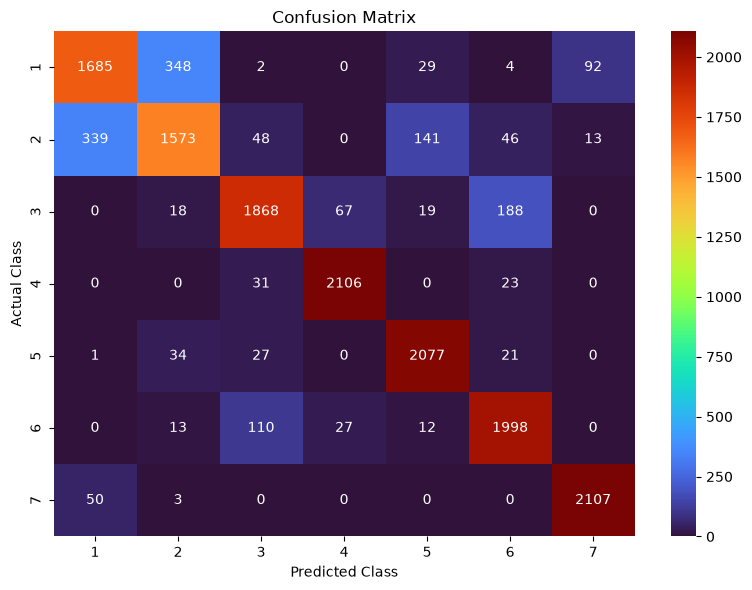

In [90]:
# Plot confusion matrix

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(target_y, y_pred), annot=True, fmt="d", cmap="turbo")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.xticks(
    ticks=np.array(range(7)) + 0.5, labels=["1", "2", "3", "4", "5", "6", "7"]
)
plt.yticks(
    ticks=np.array(range(7)) + 0.5, labels=["1", "2", "3", "4", "5", "6", "7"]
)

plt.tight_layout()

The error diagnostics highlight three primary confusion pairs:

1. Class 1 (Spruce/Fir) -> Class 2 (Lodgepole Pine): 348
2. Class 2 (Lodgepole Pine) -> Class 1 (Spruce/Fir): 339
3. Class 3 (Ponderosa Pine) -> Class 6 (Douglas-fir): 188

## 9 - Feature importance

We assess global feature importance using Gini impurity reduction from the trained XGBoost model and validate it with Permutation Feature Importance on held-out validation folds.

In [97]:
gini_importances = pd.Series(
    model_pl_xgbc.named_steps["model"].feature_importances_, 
    index=model_pl_xgbc.named_steps["model"].feature_names_in_
)

gini_importances.sort_values(ascending=False).head(10)

Elevation               0.084619
Soil_Type12             0.065415
Wilderness_Area4        0.061902
Soil_Type10             0.055457
Soil_Type30             0.049299
Soil_Type13             0.047014
Water_Body_Elevation    0.042818
Soil_Type3              0.041349
Soil_Type39             0.039811
Soil_Type4              0.036394
dtype: float32

In [115]:
model_pl = model_pl_xgbc.named_steps["model"]
preprocessing_pipeline = model_pl_xgbc[:-1]
X_preprocessed = preprocessing_pipeline.transform(features_X)

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro"
}

result_perm_importance = permutation_importance(
    model_pl, 
    X_preprocessed,
    (target_y - 1), 
    scoring=scoring,
    random_state=SEED
)

In [117]:
df_perm_importances_accuracy = pd.DataFrame(
    {"importance": result_perm_importance["accuracy"].importances_mean, "std": result_perm_importance["accuracy"].importances_std}, 
    index=model_pl.feature_names_in_
).sort_values(by="importance", ascending=False)

df_perm_importances_f1 = pd.DataFrame(
    {"importance": result_perm_importance["macro_f1"].importances_mean, "std": result_perm_importance["macro_f1"].importances_std}, 
    index=model_pl.feature_names_in_
).sort_values(by="importance", ascending=False)

In [120]:
df_perm_importances_accuracy.head()

,importance,std
Water_Body_Elevation,0.300648,0.002541
Elevation,0.183849,0.001089
Wilderness_Area4,0.034365,0.000613
Wilderness_Area1,0.025794,0.001012
Fire_Points_Minus_Roadways,0.012831,0.001016


In [121]:
df_perm_importances_f1.head()

,importance,std
Water_Body_Elevation,0.291132,0.002688
Elevation,0.195609,0.002029
Wilderness_Area4,0.035660,0.000650
Wilderness_Area1,0.025733,0.001004
Fire_Points_Minus_Roadways,0.012824,0.001015


- As shown in the permutation importance, the features involving elevation causes the largest drop in out-of-fold scores.
- This means elevation is the primary driver of tree-level decisions across the model.

## 10 - Final training and model deployment

In [131]:
model_pl = Pipeline(steps=[
    ("apply_fe", FunctionTransformer(setup_features)),
    ("model", XGBClassifier(
        n_estimators=300,
        learning_rate=0.1,
        max_depth=10,
        min_child_weight=1,
        random_state=SEED
    ))
])

model_pl.fit(features_X, (target_y - 1))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('apply_fe', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](7,)","[0,1,2,...,4,5,6]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](54,)","['Elevation','Aspect','Slope',...,'Soil_Type38','Soil_Type39', 'Soil_Type40']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,54
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function set...002223D2B33D0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [136]:
X_test = test_df.drop(columns="Id")
y_pred_test = model_pl.predict(X_test)

In [137]:
submission_df = pd.DataFrame({
    "Id": test_df["Id"],
    "Cover_Type": (y_pred_test + 1)
})

submission_df

,Id,Cover_Type
0,15121,5
1,15122,2
2,15123,1
3,15124,1
4,15125,1
...,...,...
565887,581008,3
565888,581009,3
565889,581010,3
565890,581011,3


In [138]:
assert len(submission_df) == 565892, "Row count does not match test.csv!"
assert set(submission_df.columns) == {"Id", "Cover_Type"}, "Incorrect columns!"
assert submission_df["Cover_Type"].isin(range(1, 8)).all(), "Invalid class predictions!"
assert submission_df.isnull().sum().sum() == 0, "Missing values in submission!"
assert (submission_df["Id"].values == test_df["Id"].values).all(), "ID sequence mismatch!"

In [139]:
submission_df.to_csv("asb_cs5a_submission.csv", index=False)

## 11 - Real-world operational limitations

Deploying this classification pipeline in a production forestry management system introduces several constraints

1. Spatial Autocorrelation: Random cross-validation assumes samples are independent and identically distributed (i.i.d.). However, adjacent forest plots share microclimates. Evaluating on random splits causes optimistic performance estimates. A production setup requires spatial block cross-validation (e.g. partitioning folds by disjoint geographic basins).
2. Sensor Drift & Temporal Instability: Cartographic measurements derived from historical LiDAR, aerial photography, or USGS surveys degrade over time due to wildfires, insect infestations (e.g. pine beetle epidemics), and climate-induced elevational shifts.
3. Selective Verification Bias: Verifying model classifications requires sending field crews into remote, high-altitude terrain. Errors on steep slopes (e.g. Krummholz or Douglas-fir) are far more expensive to audit than errors near established roadways.